# Recomendador musical basado en percepción emocional
## Fase I completa - Identificación y clasificación de perfiles de percepción emocional (DEAM)

**Integrantes:** Darío Alexander Ojeda Muñoz · Alejandra Martínez Henao
**Proyecto Aplicado I - Maestría en Ciencia de Datos**

Este notebook recorre las 9 etapas metodológicas de la Fase I y reproduce exactamente los resultados de la presentación *Avance Fase I*. El código reutilizable está en `src/analisis_deam.py` y `src/perfiles_recomendador.py`.

| Etapa | Contenido |
|---|---|
| 1 | Inventario del dataset |
| 2 | Unidad de análisis |
| 3 | Validación y limpieza |
| 4 | Ingeniería de variables (perfil por evaluador) |
| 5 | Análisis exploratorio |
| 6 | Clustering con K-Means |
| 7 | Caracterización de grupos |
| 8 | Clasificación interpretativa (árbol de decisión) |
| 9 | Prototipo, conclusiones y limitaciones |

In [1]:
from pathlib import Path

project_root = Path.cwd().resolve()
if not (project_root / "src").exists():
    project_root = project_root.parent
print(project_root)

C:\Users\Usuario\Documents\MCD_recomendador_musical_prt


## Etapa 1 - Inventario del dataset DEAM

Se revisa el contenido real de `DEAM_Annotations.zip` antes de proponer una unidad de análisis o construir modelos.

Regla metodológica: no se asume que cada fila representa a un oyente; primero se verifica si existe un identificador estable de evaluador.

In [2]:
from zipfile import ZipFile

import pandas as pd

zip_candidatos = [project_root / "DEAM_Annotations.zip", project_root / "data" / "raw" / "DEAM_Annotations.zip"]
ZIP_PATH = next(p for p in zip_candidatos if p.exists())

with ZipFile(ZIP_PATH) as z:
    csv_zip = sorted(n for n in z.namelist() if n.lower().endswith(".csv"))
print("ZIP:", ZIP_PATH.name)
print("Total de CSV:", len(csv_zip))
carpetas = pd.Series(["/".join(n.split("/")[:-1]) for n in csv_zip]).value_counts()
carpetas.rename("archivos").to_frame()

ZIP: DEAM_Annotations.zip
Total de CSV: 3610


,archivos
annotations/annotations per each rater/dynamic (per second annotations)/arousal,1802
annotations/annotations per each rater/dynamic (per second annotations)/valence,1802
annotations/annotations averaged per song/dynamic (per second annotations),2
annotations/annotations averaged per song/song_level,2
annotations/annotations per each rater/song_level,2


In [3]:
with ZipFile(ZIP_PATH) as z:
    for miembro in [
        "annotations/annotations averaged per song/song_level/static_annotations_averaged_songs_1_2000.csv",
        "annotations/annotations per each rater/song_level/static_annotations_songs_1_2000.csv",
        "annotations/annotations per each rater/song_level/static_annotations_songs_2000_2058.csv",
    ]:
        df = pd.read_csv(z.open(miembro), skipinitialspace=True)
        print(f"\n{miembro.split('/')[-1]}  ->  forma {df.shape}")
        print(df.head(3).to_string(index=False))


static_annotations_averaged_songs_1_2000.csv  ->  forma (1744, 5)
 song_id  valence_mean  valence_std  arousal_mean  arousal_std
       2           3.1         0.94           3.0         0.63
       3           3.5         1.75           3.3         1.62
       4           5.7         1.42           5.5         1.63

static_annotations_songs_1_2000.csv  ->  forma (17464, 4)
                        workerID  SongId  Valence  Arousal
6010bbc8e7ef4b21fa38f9c3a9754ef3       2        5        2
3c888e77b992ae3cd2adfe16774e23b9       2        2        3
2afd218c3aecb6828d2be327f8b9c46f       2        3        3

static_annotations_songs_2000_2058.csv  ->  forma (298, 8)
 SongId                         WorkerId  Arousal_Average  Valence_Average  Arousal_Maximum  Valence_Maximum  Arousal_Minimum  Valence_Minimum
   2001 523edc3414996c8e52eb14f20c93fe96                7                3                8                7                2                2
   2001 ae0b751438f08bb474e5cd3e48e0d417

### Interpretación

- Hay anotaciones promedio por canción (estáticas) y series dinámicas cada 0,5 s.
- Las anotaciones por evaluador incluyen un identificador estable (`workerID` / `WorkerId`).
- El archivo de canciones 2000-2058 trae el promedio, máximo y mínimo de cada evaluador; se usa su promedio.
- El ZIP no incluye audio ni historial de escucha.

## Etapa 2 - Unidad de análisis

Alternativas: canción, evaluador-canción, muestra temporal o **evaluador agregado**.

Como el mismo `workerID` aparece en muchas canciones (hasta ~1.000), se puede agregar por evaluador y construir un **perfil de anotación**: cómo percibe esa persona la emoción de la música. Para que las estadísticas sean estables se exige un mínimo de **10 canciones** por evaluador.

Precisión terminológica: son *perfiles de percepción/anotación*, no perfiles de personalidad ni de gusto musical, porque el dataset no contiene datos demográficos ni de escucha.

## Etapa 3 - Validación y limpieza

Se cargan los datos con las funciones de `src/analisis_deam.py`, que unen los dos archivos por evaluador y verifican automáticamente las cifras reportadas (`validate_results`).

In [4]:
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

sys.path.insert(0, str(project_root / "src"))
from analisis_deam import compute_analysis, load_deam, save_plots, save_tables, validate_results

zip_candidatos = [project_root / "DEAM_Annotations.zip", project_root / "data" / "raw" / "DEAM_Annotations.zip"]
ZIP_PATH = next(p for p in zip_candidatos if p.exists())

# Carpeta de salida: outputs/ en el repositorio; reports/figures y data/processed en la estructura Fase I.
if (project_root / "outputs").exists():
    FIG_DIR = TAB_DIR = project_root / "outputs"
else:
    FIG_DIR = project_root / "reports" / "figures"
    TAB_DIR = project_root / "data" / "processed"

data = load_deam(ZIP_PATH)
analysis = compute_analysis(data)
validate_results(analysis)
m = analysis["metrics"]
individual = analysis["individual"]

print("Validación automática superada")
print(f"Canciones: {m['songs']:,}  |  Valoraciones individuales: {m['individual_ratings']:,}  |  Evaluadores: {m['unique_raters']}")

Validación automática superada
Canciones: 1,802  |  Valoraciones individuales: 17,762  |  Evaluadores: 195


In [5]:
chequeos = pd.Series({
    "Valores nulos": int(individual.isna().sum().sum()),
    "Valencia fuera de 1-9": int((~individual["valence"].between(1, 9)).sum()),
    "Activación fuera de 1-9": int((~individual["arousal"].between(1, 9)).sum()),
    "Pares evaluador-canción repetidos": int(individual.duplicated(["worker_id", "song_id"]).sum()),
    "Canciones sin valoración individual": int(len(set(analysis["static"]["song_id"]) - set(individual["song_id"]))),
    "Mediana de evaluadores por canción": m["median_raters_per_song"],
}, name="resultado")
chequeos.to_frame()

,resultado
Valores nulos,0.0
Valencia fuera de 1-9,0.0
Activación fuera de 1-9,0.0
Pares evaluador-canción repetidos,94.0
Canciones sin valoración individual,0.0
Mediana de evaluadores por canción,10.0


### Resultado de la validación

- No hay valores nulos ni fuera de la escala 1-9, y todas las canciones tienen valoraciones individuales.
- Hay 94 pares evaluador-canción repetidos (0,5 % de las valoraciones). Se **conservan**: su efecto en los promedios es despreciable y así las cifras coinciden con la presentación (17.762 valoraciones).
- Cada canción tiene una mediana de 10 evaluadores, suficiente para calcular un consenso por canción.

## Etapa 4 - Ingeniería de variables: perfil por evaluador

Cada evaluador escuchó canciones distintas, así que su promedio bruto no basta: a alguien le pudieron tocar canciones más alegres. Por eso cada valoración se compara con el **consenso de los demás evaluadores de esa misma canción** (promedio que excluye al propio evaluador).

| Variable | Qué mide |
|---|---|
| `valencia_media`, `activacion_media` | Nivel promedio de sus respuestas |
| `valencia_sd`, `activacion_sd` | Qué tanto varía al responder |
| `sesgo_valencia`, `sesgo_activacion` | Cuánto se aleja del consenso (+ más positivo/enérgico, − más negativo/calmado) |
| `discrepancia` | Distancia absoluta promedio al consenso |

Se incluyen los evaluadores con **10 o más canciones**.

In [6]:
from perfiles_recomendador import (
    EMOTIONS, MIN_RATINGS_PER_RATER, PROFILE_FEATURES, compute_phase1, recommend_emotion,
    save_phase1_plots, save_phase1_tables, validate_phase1,
)

phase1 = compute_phase1(analysis)
validate_phase1(phase1)
m1 = phase1["metrics"]
perfiles = phase1["cluster"]["profiles"]

conteo = individual.groupby("worker_id")["song_id"].nunique()
print(f"Evaluadores con >= {MIN_RATINGS_PER_RATER} canciones: {m1['evaluadores_con_perfil']} de {m1['evaluadores_totales']}")
print(f"Valoraciones que cubren: {conteo[conteo >= MIN_RATINGS_PER_RATER].sum() / conteo.sum():.1%}")
perfiles[PROFILE_FEATURES + ["n_canciones"]].describe().round(2).T

Evaluadores con >= 10 canciones: 116 de 195
Valoraciones que cubren: 98.1%


,count,mean,std,min,25%,50%,75%,max
valencia_media,116.0,4.85,0.79,1.62,4.54,4.90,5.36,6.97
activacion_media,116.0,4.93,0.81,1.70,4.49,4.93,5.34,7.65
valencia_sd,116.0,1.78,0.41,0.84,1.53,1.78,2.03,3.08
activacion_sd,116.0,1.79,0.41,0.80,1.53,1.76,2.07,3.06
sesgo_valencia,116.0,-0.04,0.77,-3.37,-0.43,-0.00,0.41,2.42
sesgo_activacion,116.0,0.09,0.79,-3.50,-0.27,0.11,0.62,2.44
discrepancia,116.0,1.28,0.35,0.78,1.08,1.22,1.43,3.45
n_canciones,116.0,149.39,232.29,10.00,18.75,48.50,164.50,1002.00


## Etapa 5 - Análisis exploratorio

,songs,percentage
quadrant,,
Negativa / baja,686,38.1
Positiva / alta,647,35.9
Positiva / baja,240,13.3
Negativa / alta,229,12.7


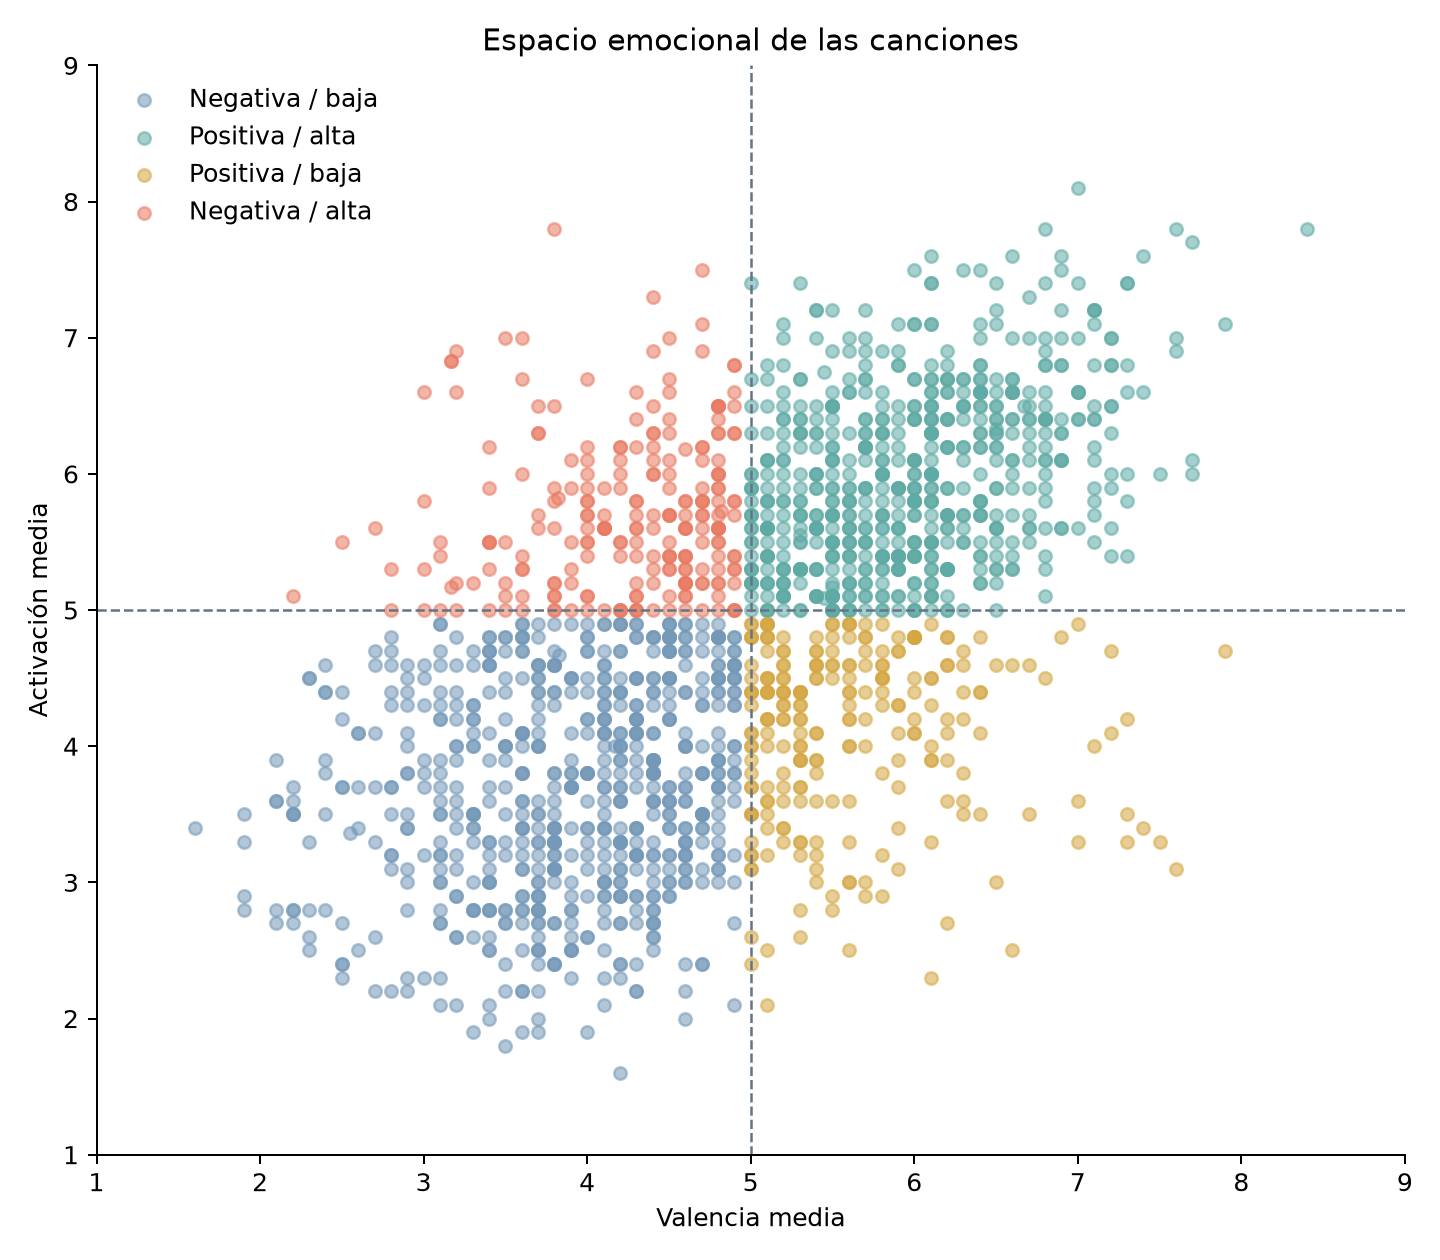

In [7]:
save_tables(analysis, TAB_DIR)
save_plots(analysis, FIG_DIR)
display(analysis["quadrants"].round(1))
display(Image(filename=str(FIG_DIR / "02_espacio_valencia_activacion.png"), width=650))

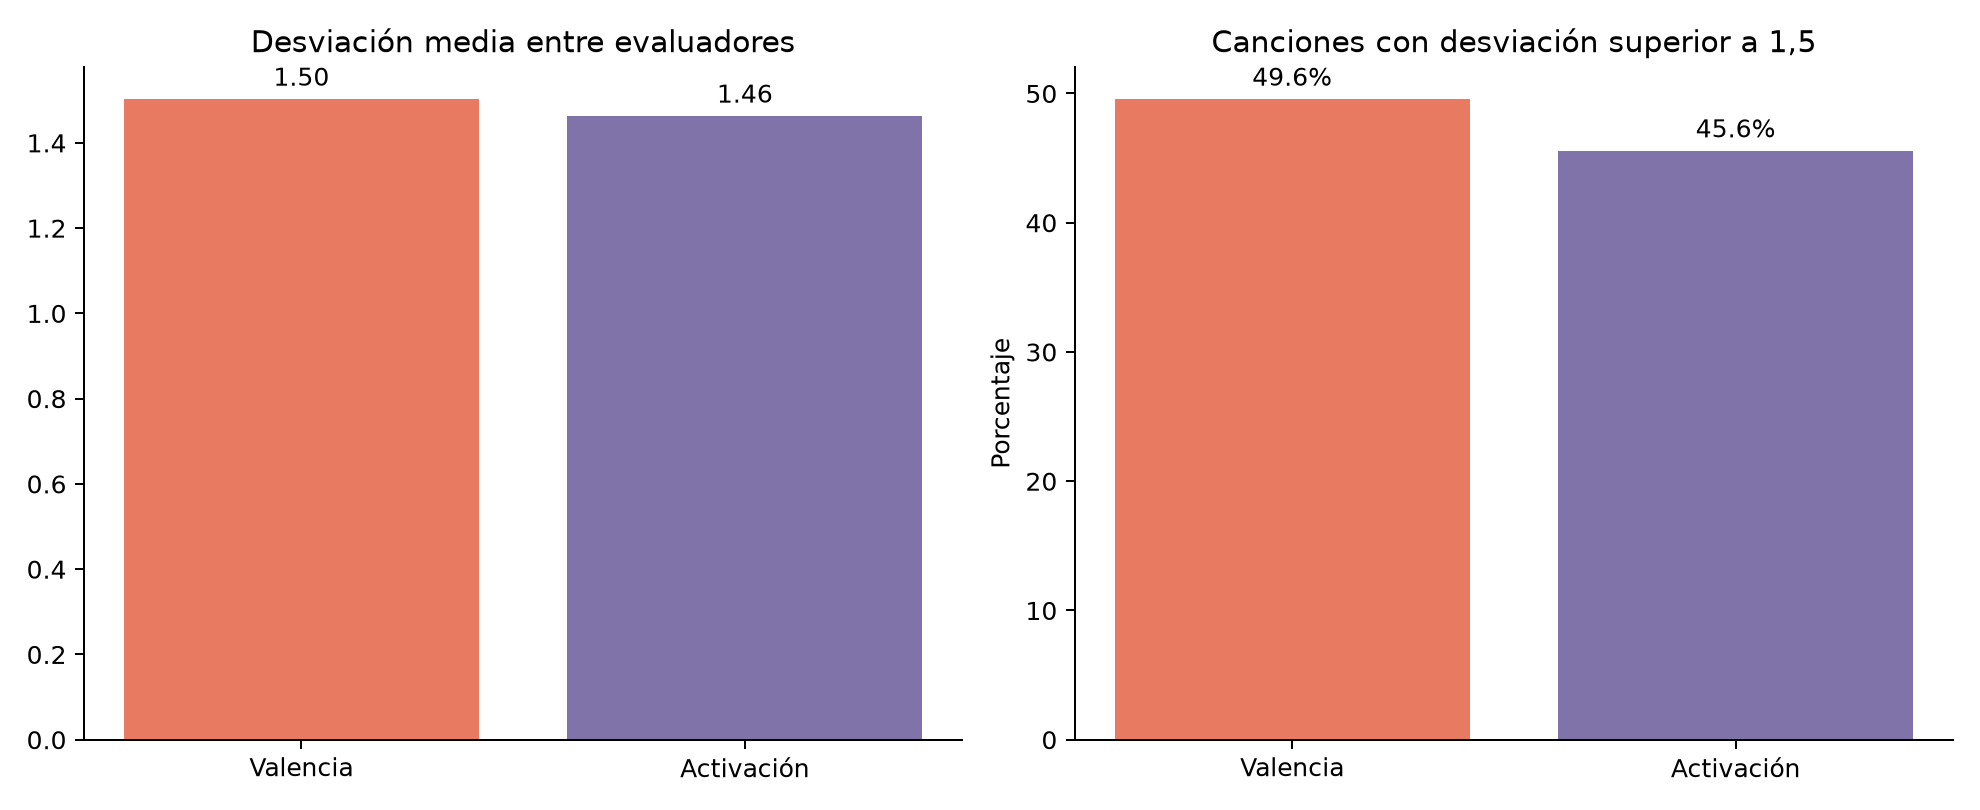

Desviación media entre evaluadores: valencia 1.50, activación 1.46
Canciones con desviación > 1,5 en valencia: 50 %
Correlación valencia-activación entre canciones: 0.57


In [8]:
display(Image(filename=str(FIG_DIR / "03_subjetividad_emocional.png"), width=850))
print(f"Desviación media entre evaluadores: valencia {m['mean_interrater_valence_sd']:.2f}, activación {m['mean_interrater_arousal_sd']:.2f}")
print(f"Canciones con desviación > 1,5 en valencia: {m['valence_sd_over_1_5_pct']:.0f} %")
print(f"Correlación valencia-activación entre canciones: {m['valence_arousal_correlation']:.2f}")

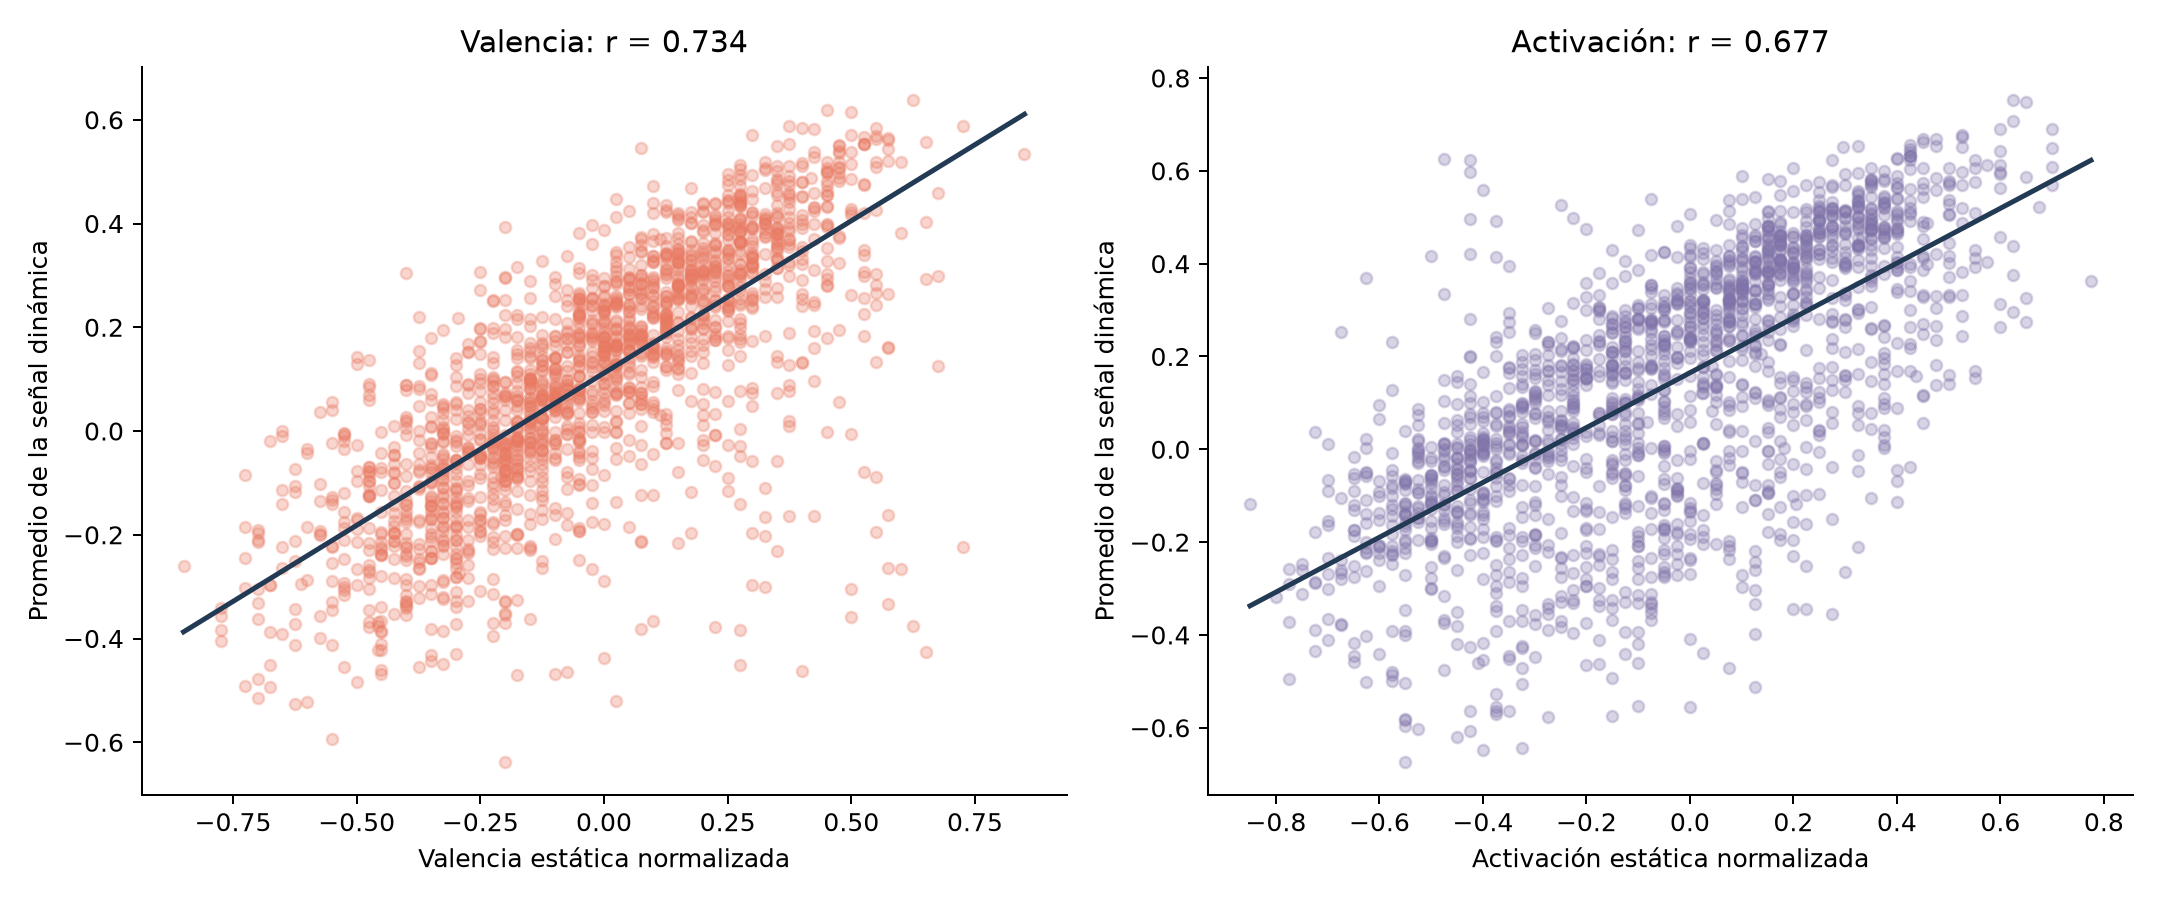

Estática vs. dinámica: valencia r = 0.73, activación r = 0.68


In [9]:
display(Image(filename=str(FIG_DIR / "04_consistencia_estatica_dinamica.png"), width=850))
print(f"Estática vs. dinámica: valencia r = {m['static_dynamic_valence_correlation']:.2f}, activación r = {m['static_dynamic_arousal_correlation']:.2f}")

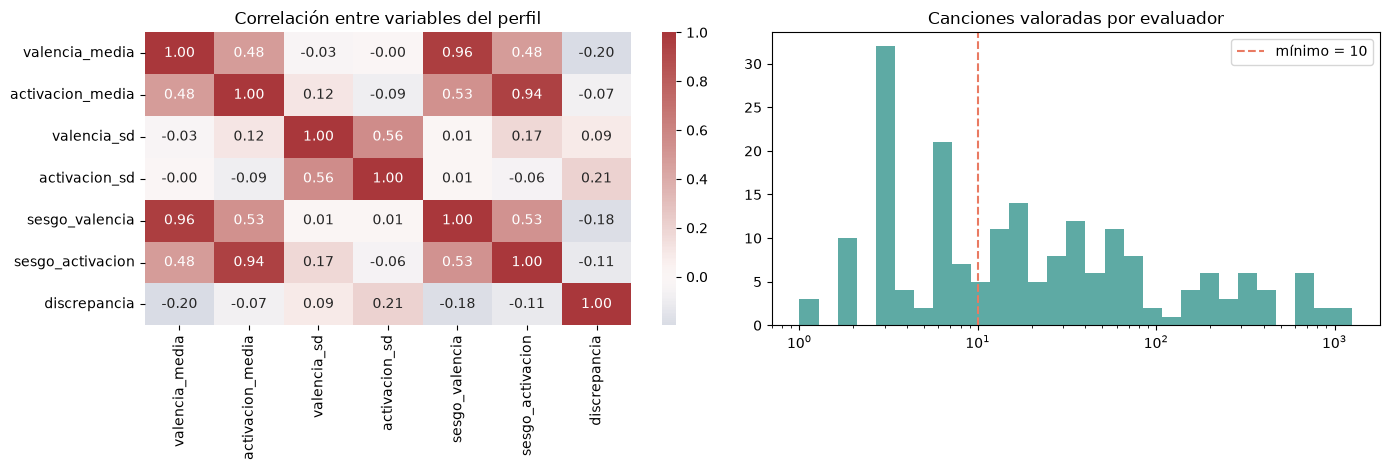

In [10]:
%matplotlib inline
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(perfiles[PROFILE_FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Correlación entre variables del perfil")
axes[1].hist(conteo, bins=np.logspace(0, 3.1, 30), color="#5EAAA4")
axes[1].axvline(MIN_RATINGS_PER_RATER, color="#E97A62", ls="--", label=f"mínimo = {MIN_RATINGS_PER_RATER}")
axes[1].set_xscale("log")
axes[1].set_title("Canciones valoradas por evaluador")
axes[1].legend()
plt.tight_layout()
plt.show()

### Lectura del exploratorio

- **Catálogo desbalanceado:** el 74 % de las canciones está en dos cuadrantes (negativa/baja y positiva/alta); hay pocas canciones tensas o de enojo.
- **La percepción es subjetiva:** la desviación media entre evaluadores es ≈ 1,5 puntos y cerca de la mitad de las canciones supera ese valor.
- **Las anotaciones son coherentes:** la valoración global coincide con la dinámica (r ≈ 0,73 en valencia).
- **Participación desigual:** pocos evaluadores aportan cientos de canciones; el mínimo de 10 deja 116 evaluadores.
- La valencia media y el sesgo de valencia están muy correlacionados (≈ 0,96): miden casi lo mismo, lo que se tiene en cuenta al interpretar el árbol.

## Etapa 6 - Clustering con K-Means

Las 7 variables se estandarizan y se prueban k = 2 a 6. Se elige el k con mayor coeficiente **silhouette**.

,k,inercia,silhouette
0,2,617.009,0.237
1,3,516.540,0.219
2,4,429.264,0.210
3,5,371.026,0.215
4,6,318.638,0.217


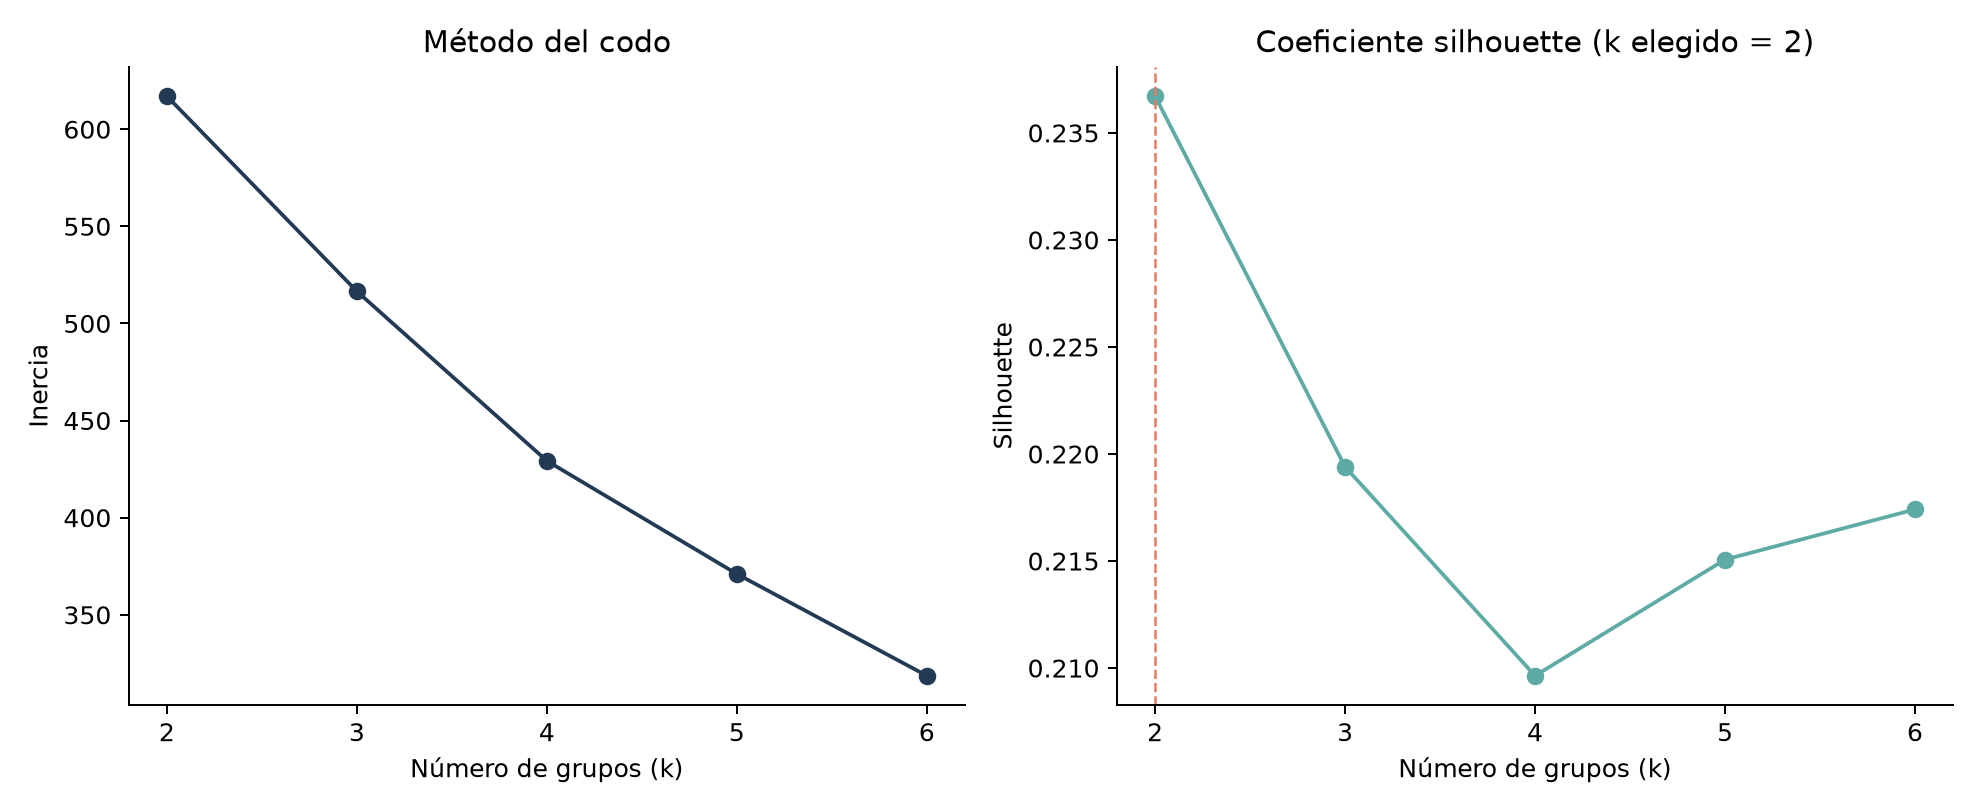

k elegido: 2  |  silhouette = 0.237


In [11]:
save_phase1_tables(phase1, TAB_DIR)
save_phase1_plots(phase1, FIG_DIR)
display(phase1["cluster"]["selection"].round(3))
display(Image(filename=str(FIG_DIR / "05_seleccion_numero_grupos.png"), width=800))
print(f"k elegido: {m1['k_elegido']}  |  silhouette = {m1['silhouette']:.3f}")

In [12]:
# Estabilidad: ¿se repiten los grupos con otras semillas y con remuestreo de evaluadores?
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

Xz = StandardScaler().fit_transform(perfiles[PROFILE_FEATURES])
etiquetas = perfiles["grupo"].to_numpy()
ari_semillas = [adjusted_rand_score(etiquetas, KMeans(2, n_init=20, random_state=s).fit_predict(Xz)) for s in range(20)]
rng = np.random.default_rng(42)
ari_boot = []
for _ in range(100):
    idx = rng.choice(len(Xz), len(Xz), replace=True)
    ari_boot.append(adjusted_rand_score(etiquetas[idx], KMeans(2, n_init=10, random_state=42).fit_predict(Xz[idx])))
print(f"ARI con 20 semillas distintas: media = {np.mean(ari_semillas):.2f}")
print(f"ARI con 100 remuestreos bootstrap: media = {np.mean(ari_boot):.2f}, mediana = {np.median(ari_boot):.2f}")

ARI con 20 semillas distintas: media = 0.99
ARI con 100 remuestreos bootstrap: media = 0.51, mediana = 0.53


## Etapa 7 - Caracterización de grupos

grupo,1,2
descripcion,"Valencias altas, perciben más positividad","Valencias bajas, perciben más negatividad"
evaluadores,73,43
valencia_media,5.25,4.15
activacion_media,5.32,4.28
valencia_sd,1.81,1.74
activacion_sd,1.75,1.85
sesgo_valencia,0.34,-0.7
sesgo_activacion,0.46,-0.54
discrepancia,1.26,1.32


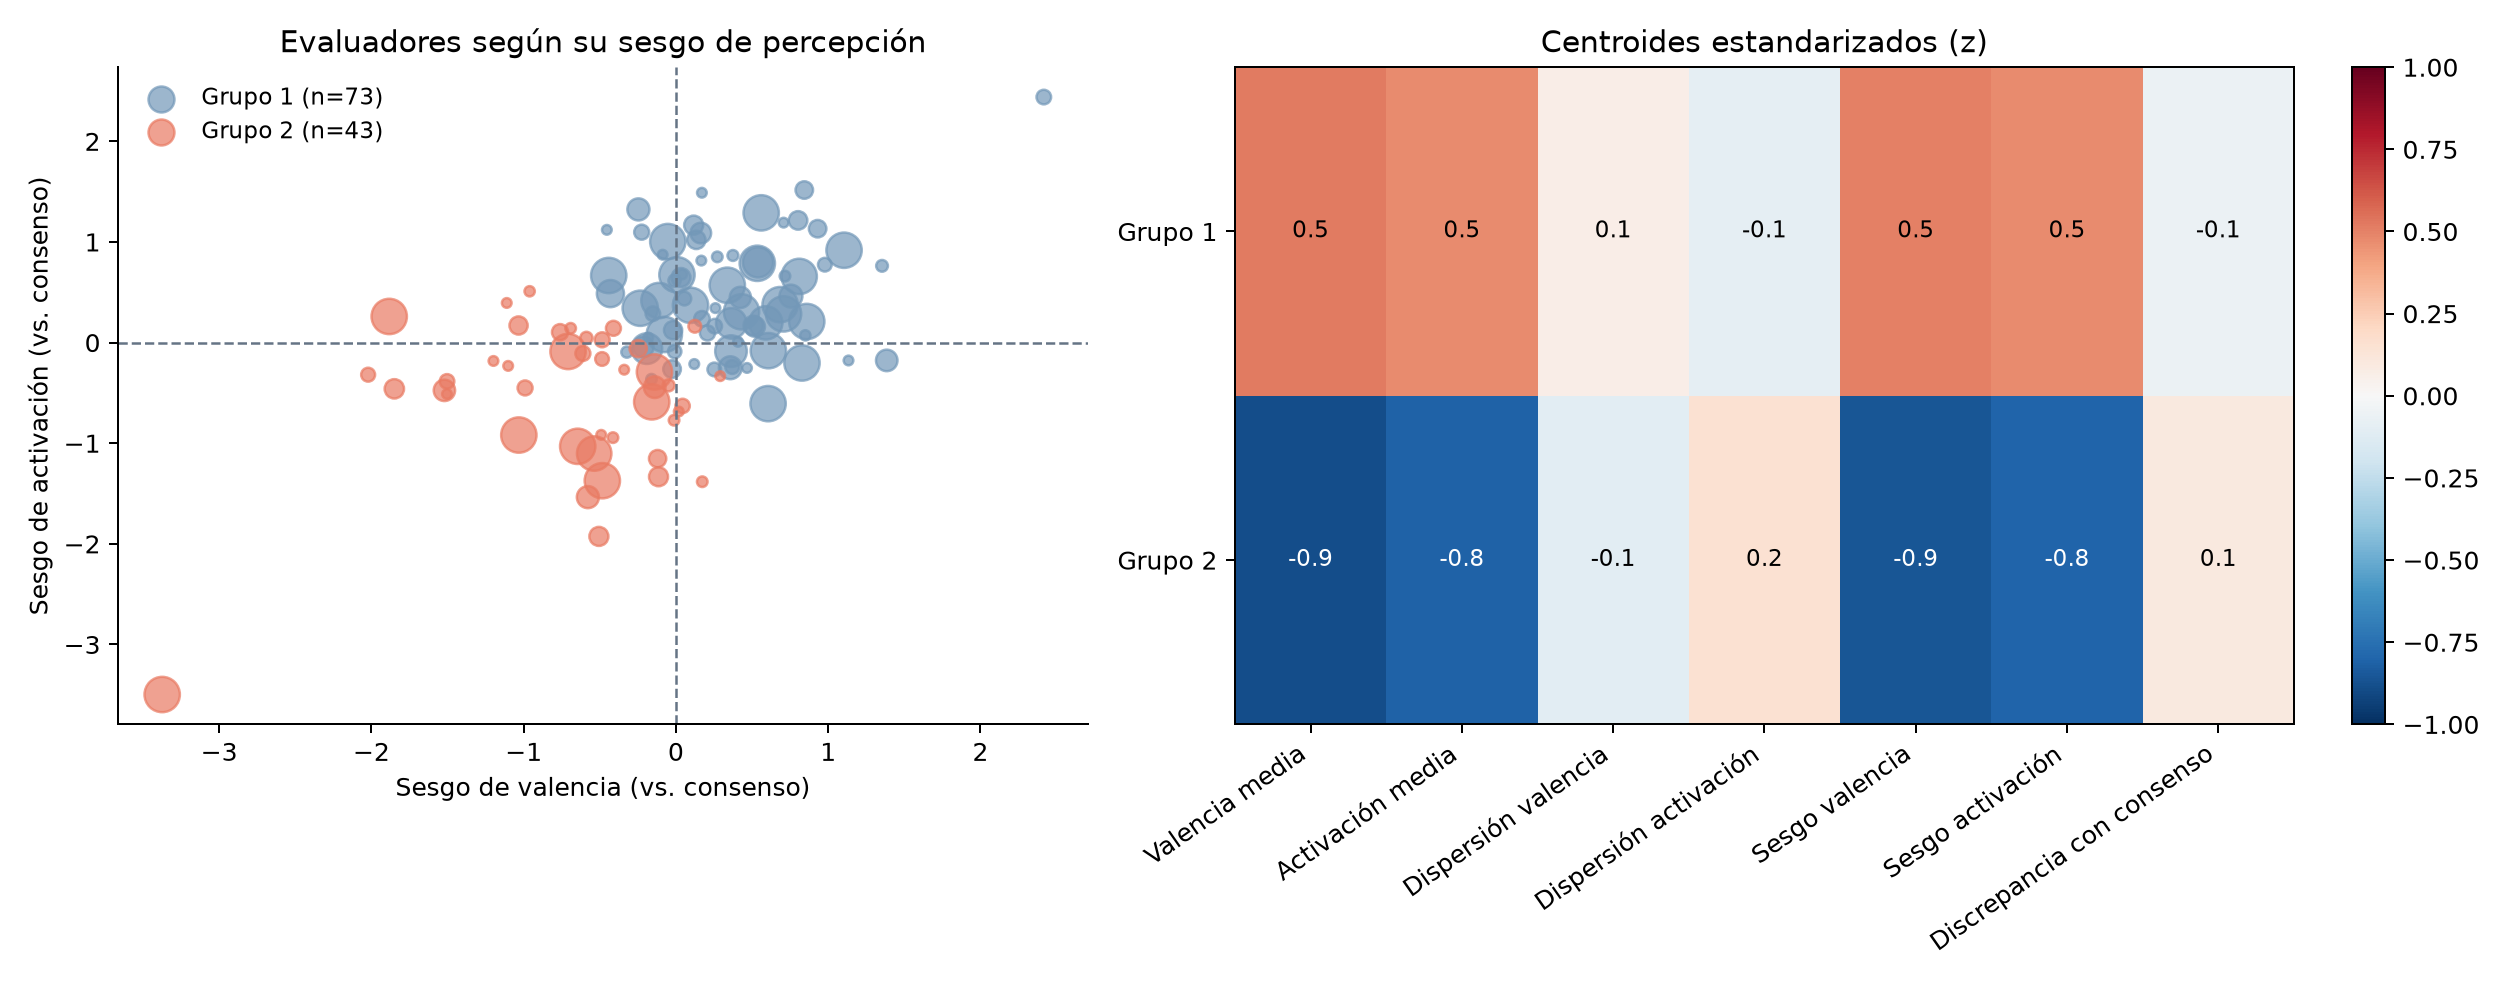

In [13]:
display(phase1["cluster"]["summary"].round(2).T)
display(Image(filename=str(FIG_DIR / "06_perfiles_anotacion.png"), width=950))

In [14]:
from scipy.stats import mannwhitneyu

pruebas = pd.DataFrame(
    [{"variable": v, "p_valor": mannwhitneyu(perfiles.loc[perfiles.grupo == 1, v], perfiles.loc[perfiles.grupo == 2, v]).pvalue} for v in PROFILE_FEATURES]
).sort_values("p_valor")
pruebas["diferencia significativa (5 %)"] = pruebas["p_valor"] < 0.05
pruebas.round(4)

,variable,p_valor,diferencia significativa (5 %)
0,valencia_media,0.0000,True
4,sesgo_valencia,0.0000,True
1,activacion_media,0.0000,True
5,sesgo_activacion,0.0000,True
3,activacion_sd,0.3664,False
2,valencia_sd,0.3664,False
6,discrepancia,0.4186,False


### Dos perfiles de percepción

- **Grupo 1 (73 evaluadores) - "más positividad y energía":** frente al consenso perciben la música más positiva (sesgo de valencia ≈ +0,34) y más enérgica (≈ +0,46).
- **Grupo 2 (43 evaluadores) - "más negatividad y calma":** la perciben más negativa (≈ −0,70) y más calmada (≈ −0,54).

Las diferencias en medias y sesgos son estadísticamente significativas; en dispersión y discrepancia no, es decir, ambos grupos son igual de consistentes y se distinguen por la **dirección** de su percepción.

Con silhouette ≈ 0,24 la separación es moderada: la percepción cambia de forma gradual entre personas, y los grupos son una simplificación útil de ese continuo.

**Estabilidad:** con 20 semillas distintas K-Means obtiene prácticamente los mismos grupos (ARI ≈ 0,99), pero al remuestrear evaluadores (bootstrap) el acuerdo baja a ≈ 0,5. Es decir, el resultado no depende del azar del algoritmo, pero sí de qué evaluadores entran en la muestra: los evaluadores cercanos a la frontera cambian de grupo con facilidad.

## Etapa 8 - Clasificación interpretativa

Un **árbol de decisión** de profundidad 3 aprende a asignar evaluadores a su perfil con reglas legibles. Se evalúa con validación cruzada estratificada de 5 particiones y se compara con una línea base que siempre predice el grupo más grande.

,modelo,exactitud,exactitud balanceada
0,Línea base (grupo mayoritario),0.629,0.500
1,Árbol de decisión,0.897,0.889


Matriz de confusión (filas = real, columnas = predicho):


,1,2
1,67,6
2,6,37


|--- valencia_media <= 4.59
|   |--- sesgo_activacion <= 0.44
|   |   |--- sesgo_valencia <= -0.22
|   |   |   |--- class: 2
|   |   |--- sesgo_valencia >  -0.22
|   |   |   |--- class: 2
|   |--- sesgo_activacion >  0.44
|   |   |--- sesgo_valencia <= -0.71
|   |   |   |--- class: 2
|   |   |--- sesgo_valencia >  -0.71
|   |   |   |--- class: 1
|--- valencia_media >  4.59
|   |--- sesgo_activacion <= -0.28
|   |   |--- valencia_media <= 5.31
|   |   |   |--- class: 2
|   |   |--- valencia_media >  5.31
|   |   |   |--- class: 1
|   |--- sesgo_activacion >  -0.28
|   |   |--- sesgo_valencia <= -0.37
|   |   |   |--- class: 1
|   |   |--- sesgo_valencia >  -0.37
|   |   |   |--- class: 1



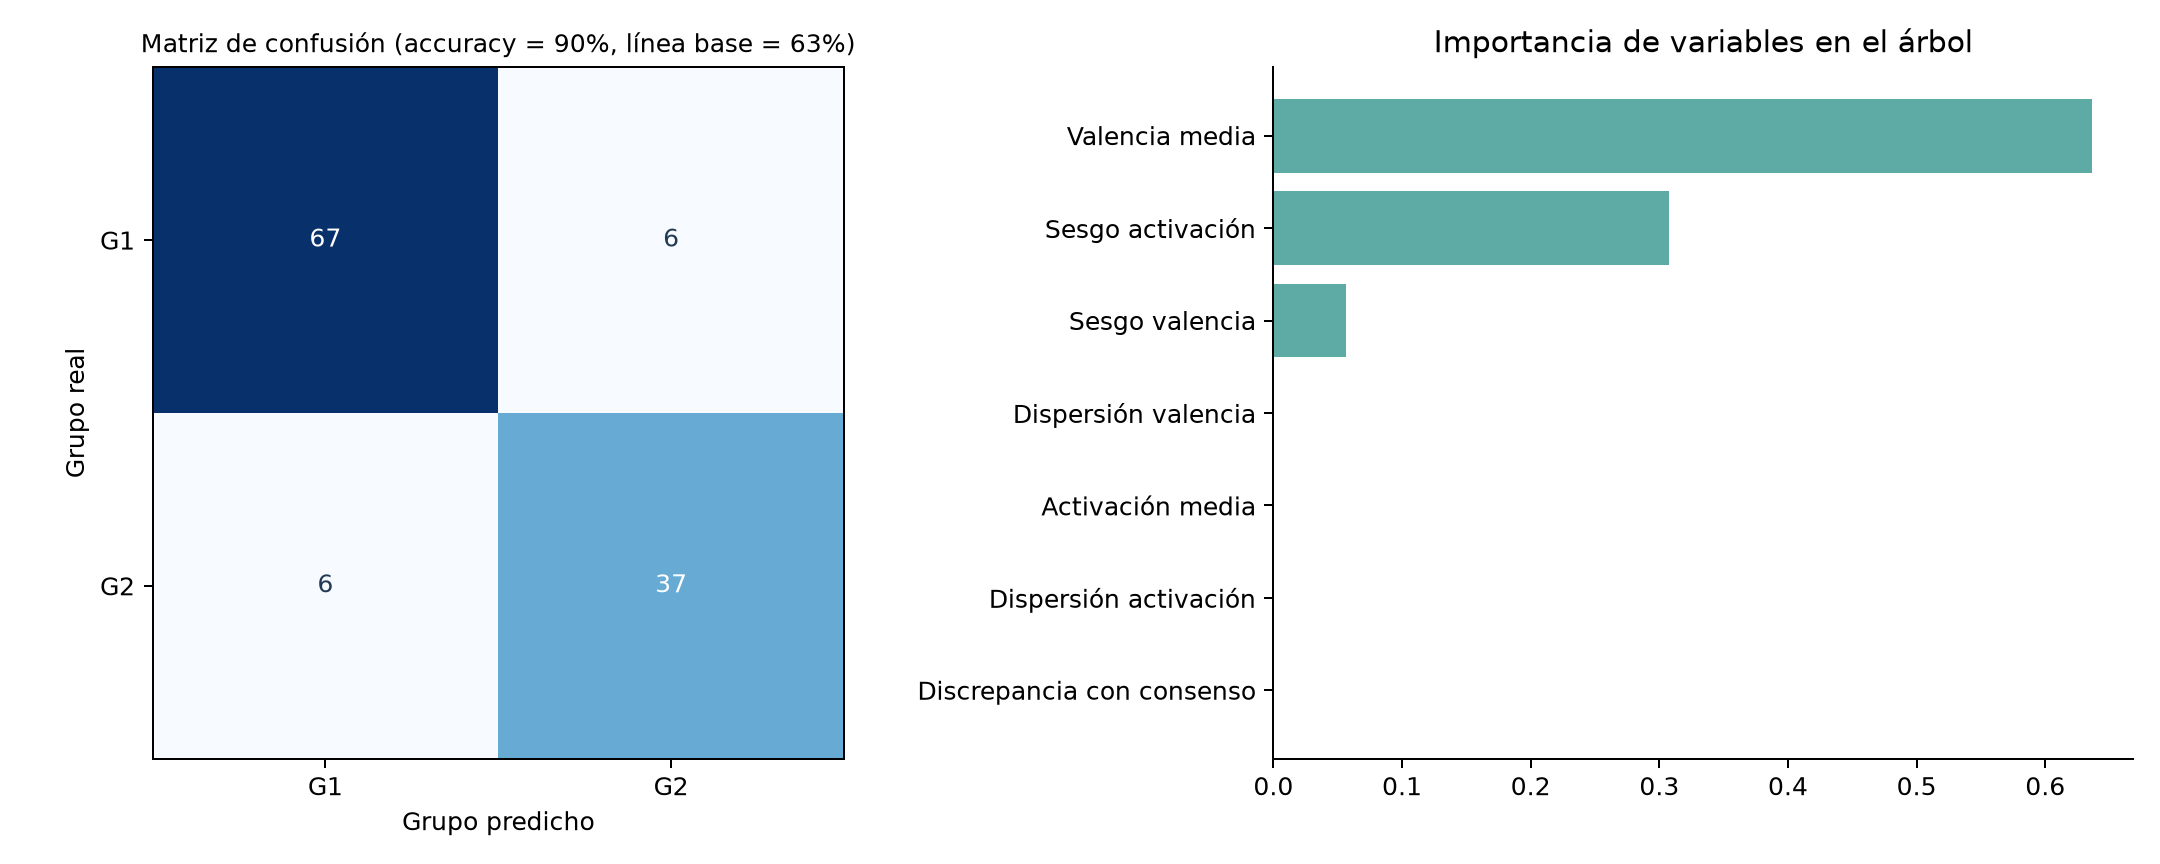

In [15]:
clf = phase1["classifier"]
resumen_clf = pd.DataFrame({
    "modelo": ["Línea base (grupo mayoritario)", "Árbol de decisión"],
    "exactitud": [clf["baseline_accuracy"], clf["accuracy"]],
    "exactitud balanceada": [0.5, clf["balanced_accuracy"]],
})
display(resumen_clf.round(3))
print("Matriz de confusión (filas = real, columnas = predicho):")
display(clf["confusion"])
print(clf["rules"])
display(Image(filename=str(FIG_DIR / "07_clasificador_perfiles.png"), width=850))

### Lectura

- El árbol acierta el **89,7 %** (exactitud balanceada 88,9 %), frente a **62,9 %** de la línea base: solo 12 de 116 evaluadores quedan mal clasificados.
- Las variables más útiles son la **valencia media** y el **sesgo de activación**.
- *Limitación:* los grupos se definieron con las mismas variables, así que el resultado mide que los perfiles son **reproducibles y explicables**, no su validez externa.

## Etapa 9 - Prototipo, conclusiones y limitaciones

### Prototipo de recomendador (vista previa de la Fase II)

El usuario elige una emoción, que se ubica como un punto en el plano valencia-activación, y se ordenan las canciones por:

`puntaje = distancia a la emoción + 0,3 × desacuerdo entre evaluadores`

Emociones disponibles: alegre, energico, relajado, tranquilo, triste, melancolico, tenso, enojado


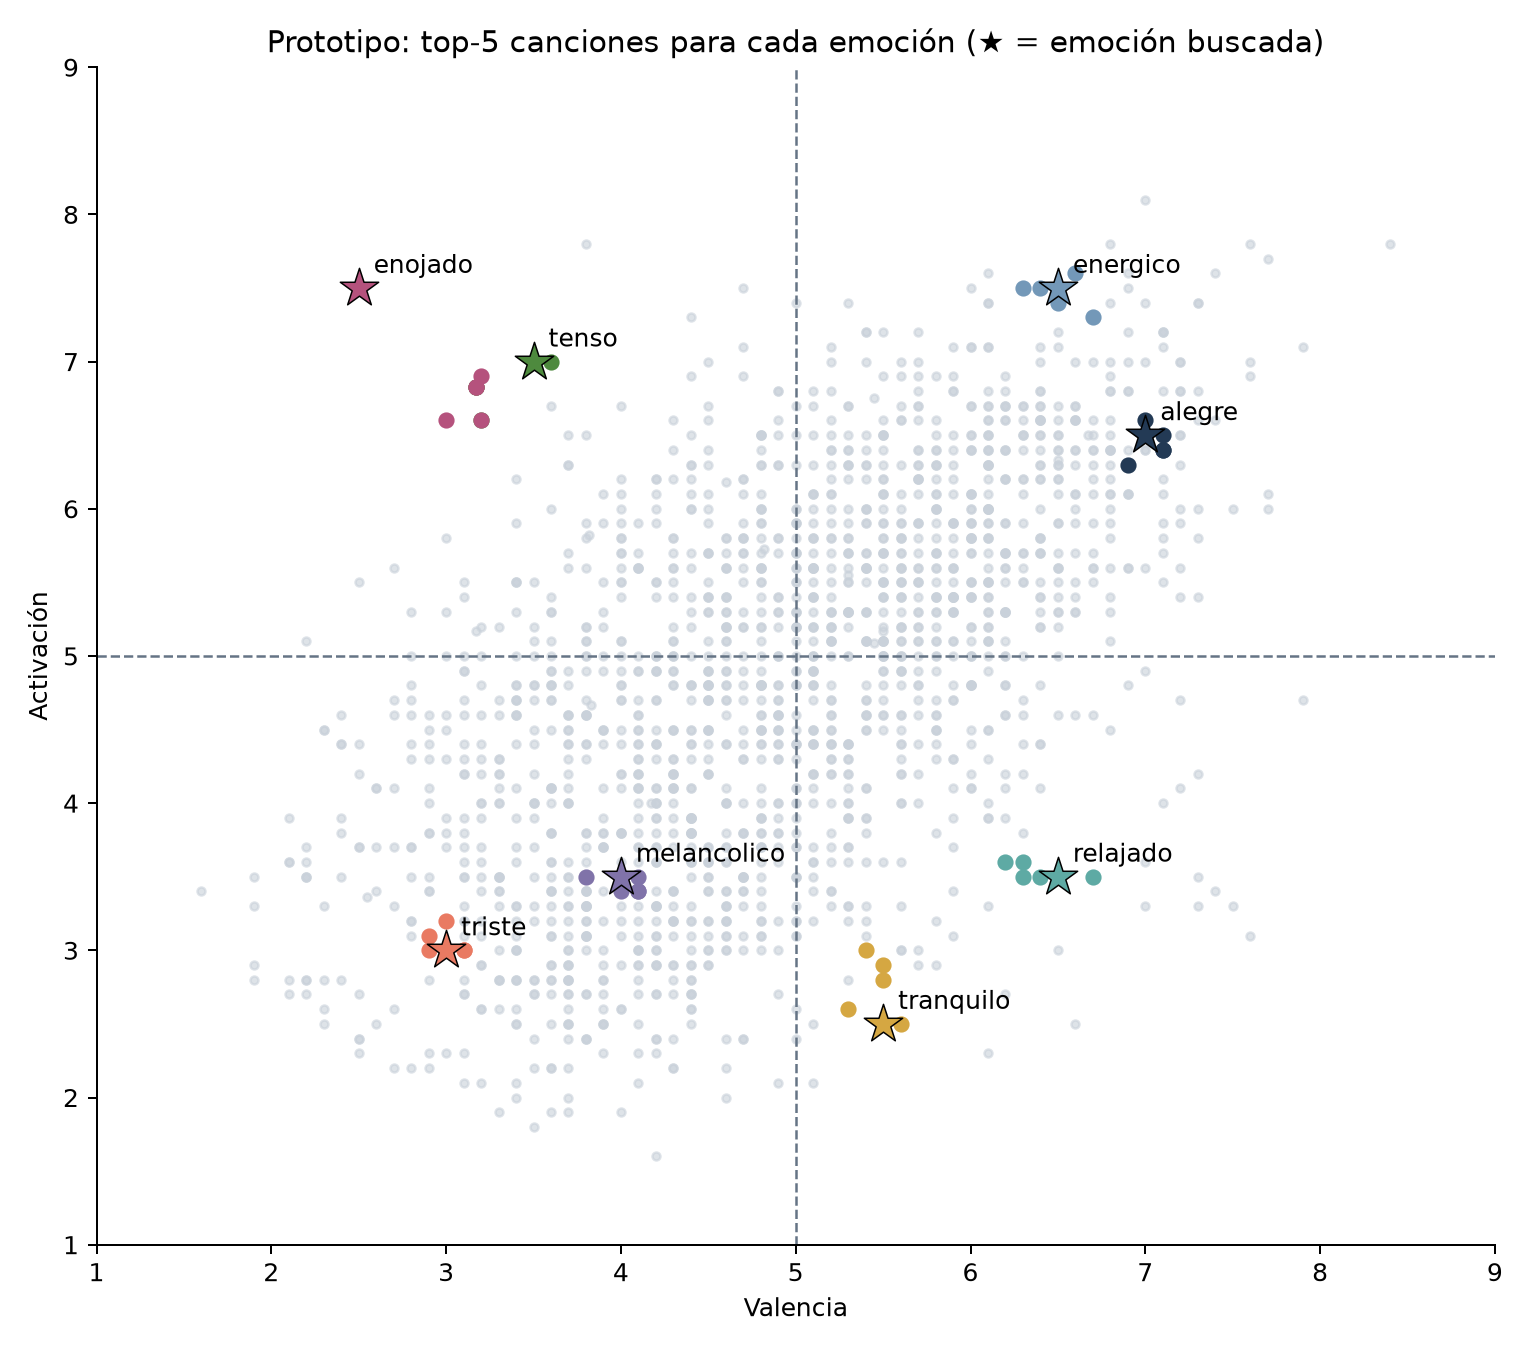

,song_id,valencia_percibida,activacion_percibida,quadrant,distancia,incertidumbre,puntaje
0,729,6.4,3.5,Positiva / baja,0.10,1.30,0.49
1,2048,6.2,3.6,Positiva / baja,0.32,1.12,0.65
2,161,6.3,3.5,Positiva / baja,0.20,1.55,0.66
3,987,6.3,3.6,Positiva / baja,0.22,1.59,0.70
4,43,6.7,3.5,Positiva / baja,0.20,1.92,0.77


In [16]:
print("Emociones disponibles:", ", ".join(EMOTIONS))
display(Image(filename=str(FIG_DIR / "08_recomendaciones_por_emocion.png"), width=650))
recommend_emotion(phase1["catalog"], "relajado").round(2)

In [17]:
# Misma emoción, distinta lista según el perfil
for grupo, sesgo in phase1["biases"].items():
    recs = recommend_emotion(phase1["catalog"], "alegre", bias=sesgo)
    print(f"Grupo {grupo} (sesgo valencia {sesgo[0]:+.2f}, activación {sesgo[1]:+.2f}): canciones {recs['song_id'].head(3).tolist()}")

Grupo 1 (sesgo valencia +0.34, activación +0.46): canciones [1817, 2020, 1895]
Grupo 2 (sesgo valencia -0.70, activación -0.54): canciones [964, 1761, 257]


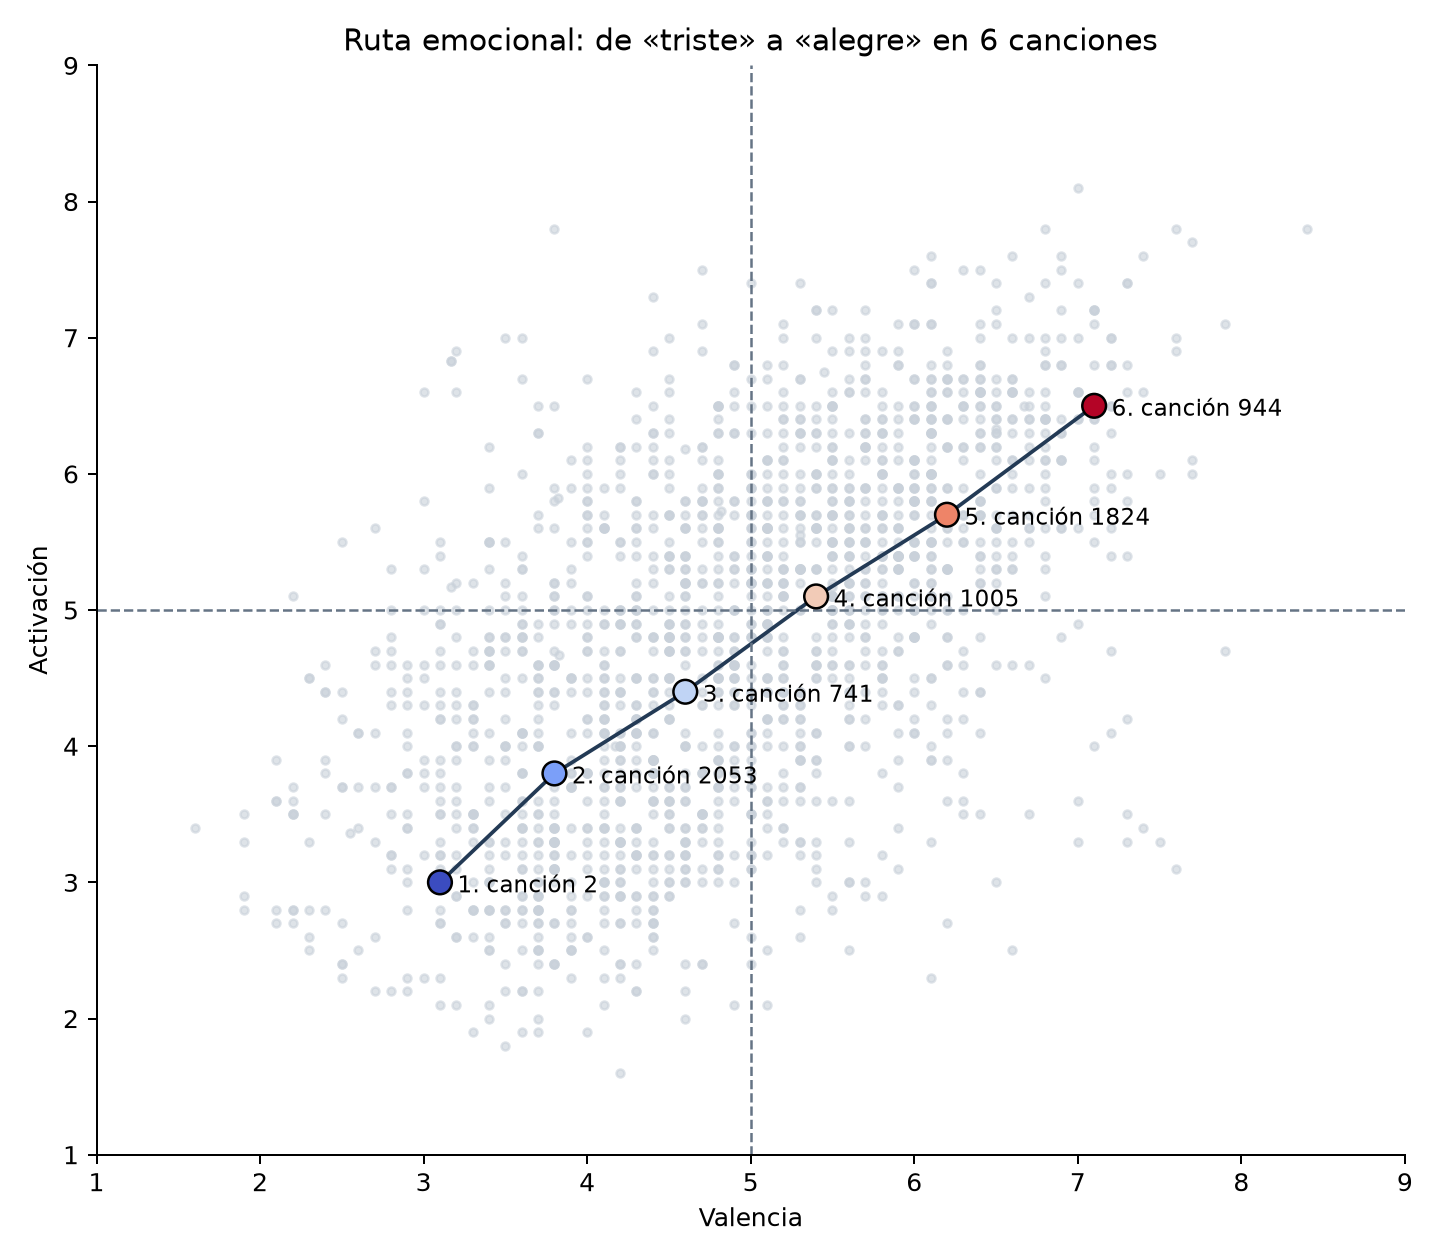

Ruta de triste a alegre: 2 -> 2053 -> 741 -> 1005 -> 1824 -> 944


In [18]:
display(Image(filename=str(FIG_DIR / "09_ruta_emocional.png"), width=600))
print("Ruta de triste a alegre:", " -> ".join(map(str, phase1["route"]["song_id"])))

### Conclusiones

1. **La percepción emocional es subjetiva:** cerca del 50 % de las canciones tiene desacuerdo alto (desviación > 1,5 en escala 1-9).
2. **Unidad de análisis:** el evaluador, con identificador estable; 116 evaluadores con ≥ 10 canciones.
3. **Dos perfiles de percepción:** uno percibe la música más positiva y enérgica que el consenso (73) y otro más negativa y calmada (43), con separación moderada (silhouette 0,24).
4. **Los perfiles se reconocen:** un árbol de decisión de profundidad 3 los asigna con 89,7 % de acierto frente a 62,9 % de la línea base.
5. **Aplicación:** el prototipo usa el sesgo de cada perfil para personalizar recomendaciones sin historial de escucha, y la ruta emocional aplica el principio iso de la musicoterapia.
6. **Catálogo:** faltan canciones tensas o de enojo (solo 13 % en el cuadrante negativa/alta).

### Limitaciones

- Separación moderada entre grupos (silhouette 0,24; ARI bootstrap ≈ 0,5): la percepción es un continuo y los perfiles lo simplifican.
- Son perfiles de **anotación** de trabajadores de crowdsourcing, no de oyentes con datos demográficos o de gusto.
- 79 evaluadores con menos de 10 canciones quedan fuera de los perfiles.
- El árbol se evalúa sobre grupos creados con las mismas variables (circularidad).
- El prototipo no se ha evaluado con usuarios reales.

### Próximos pasos (Fase II)

- Predecir valencia y activación desde el audio (características acústicas de DEAM y *transfer learning*).
- Recolectar interacciones reales con un piloto de usuarios.
- Evaluar relevancia, diversidad y satisfacción de las recomendaciones.